# Embeddings Workshop

**Words become coordinates.** An embedding turns text into a list of numbers, arranged so that texts with related meanings land near each other. This notebook uses real GloVe word vectors: 50,000 English words, 100 numbers each.

**How to use it**
1. Run every cell from the top (*Run → Run All Cells*). The first run downloads the vectors (about 130 MB) and saves a cache, so later runs start in seconds.
2. Each section has live controls. Text boxes update when you press **Enter** or click outside them; sliders, dropdowns and buttons update immediately.
3. The interactive parts need `ipywidgets`, which JupyterLab, VS Code and Google Colab already include.
4. **Q.ANT NPU (optional).** If the Q.ANT native computing toolkit and an NPU are installed, the heavy math runs on the NPU: similarity scoring, PCA, sentence embedding, softmax and sigmoid, batch normalization, convolution and pooling, and a KAN layer. Without them the notebook uses NumPy and everything still works. Section titles tell you which toolkit functions each part uses.

| Section | What you do |
|---|---|
| 0. The map | See 40 words cluster by topic without ever being told the topics |
| 1. Vectors | Look at the 100 numbers behind a word |
| 2. Angles | Drag two arrows and see why similarity is an angle |
| 3. Neighbors | Search the whole vocabulary and walk from word to word |
| 4. Analogies | Compute king − man + woman |
| 5. Sentences | Turn sentences into vectors and run a semantic search |
| NPU backend | Run the similarity math on Q.ANT hardware and check what bfloat16 costs in accuracy |
| 6. Limits | See where averaging word vectors breaks |
| Device panel | Watch NPU busy time, temperature and firmware while queries run |
| 5b. NPU embeddings | Build sentence vectors with a linear layer on the NPU |
| 7. Toolkit search | Semantic search over the Q.ANT toolkit's own functions |
| 8. Word order | Add order-awareness with a convolution and pooling layers |
| 9. Normalization | Fix the common direction with batch normalization instead |
| 10. KAN readout | Classify words with the device's periodic KAN layer |
| 11. Device walk | Walk through neighbors with features, weights and results kept on the device |
| Playground | Map, cluster and compare your own words and phrases |

In [4]:
import gzip, os, re, time, difflib, urllib.request
from collections import defaultdict
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import ipywidgets as widgets
from IPython.display import display, clear_output

%matplotlib inline

# Colors used throughout the notebook
ACCENT, POS, NEG, INK, MUTED = "#2740C0", "#C9561A", "#1C8585", "#16201B", "#7A857E"
GROUP_COLORS = ["#2740C0", "#C9561A", "#1D8463", "#AD2468", "#8C6A00", "#6A4CC4", "#0B7DA3", "#5F6B1E"]
DIVERGING = LinearSegmentedColormap.from_list("glove", [NEG, "#F4F6F2", POS])      # negative -> 0 -> positive
SIMILARITY = LinearSegmentedColormap.from_list("sim", ["#FFFFFF", "#DFE4F8", ACCENT])

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
})

## Load the vectors

GloVe learned these vectors from 6 billion words of Wikipedia and news text (Pennington, Socher and Manning, Stanford NLP, 2014). We keep the 50,000 most frequent plain words and scale every vector to length 1.

In [5]:
URL = ("https://github.com/RaRe-Technologies/gensim-data/releases/download/"
       "glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz")
GZ_FILE = "glove-wiki-gigaword-100.gz"
CACHE_FILE = "glove_cache_50k.npz"
N_WORDS = 50_000


def download(url, path):
    def progress(blocks, block_size, total):
        done = min(1.0, blocks * block_size / total) if total > 0 else 0
        print(f"\rDownloading GloVe: {done:5.1%}", end="")
    urllib.request.urlretrieve(url, path, progress)
    print()


def load_glove(n_words=N_WORDS):
    """Return (words, vectors, ranks). Vectors have length 1; ranks are frequency positions."""
    if os.path.exists(CACHE_FILE):
        data = np.load(CACHE_FILE)
        return data["words"].tolist(), data["vectors"], data["ranks"]
    if not os.path.exists(GZ_FILE):
        download(URL, GZ_FILE)
    words, vectors, ranks = [], [], []
    with gzip.open(GZ_FILE, "rt", encoding="utf8") as f:
        for rank, line in enumerate(f):             # the file is sorted by frequency
            parts = line.rstrip().split(" ")
            if len(parts) < 10:                     # header line "400000 100"
                continue
            if not (parts[0].isascii() and parts[0].isalpha()):
                continue                            # skip punctuation and numbers
            words.append(parts[0])
            ranks.append(rank)
            vectors.append(np.asarray(parts[1:], dtype=np.float32))
            if len(words) >= n_words:
                break
    V = np.stack(vectors)
    V /= np.linalg.norm(V, axis=1, keepdims=True)
    np.savez(CACHE_FILE, words=np.array(words), vectors=V, ranks=np.array(ranks))
    return words, V, np.array(ranks)


WORDS, V, RANKS = load_glove()
INDEX = {w: i for i, w in enumerate(WORDS)}
print(f"{len(WORDS):,} words x {V.shape[1]} dimensions")

50,000 words x 100 dimensions


In [6]:
# Small helpers shared by every section

BY_LETTER = defaultdict(list)
for w in WORDS:
    BY_LETTER[w[0]].append(w)


def clean(word):
    return word.strip().lower()


def vec(word):
    """The vector for one word."""
    return V[INDEX[clean(word)]]


def missing(*words):
    """Print a friendly note for each unknown word. Returns True if any word is unknown."""
    bad = [w for w in words if clean(w) not in INDEX]
    for w in bad:
        w = clean(w)
        if not w:
            print("Type a word in every box.")
            continue
        close = difflib.get_close_matches(w, BY_LETTER.get(w[0], []), n=3)
        print(f"'{w}' is not in the vocabulary." + (f" Try: {', '.join(close)}" if close else ""))
    return bool(bad)


def text_box(value, description="", width="140px"):
    return widgets.Text(value=value, description=description, continuous_update=False,
                        layout=widgets.Layout(width=width))


def row(*items):
    return widgets.HBox(list(items), layout=widgets.Layout(flex_flow="row wrap", align_items="center"))


def pca_2d(X):
    """Flatten vectors to 2D. Returns the coordinates and the share of variance kept."""
    Xc = X - X.mean(axis=0)
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    xy = dots(add_bias(X, -X.mean(axis=0)), Vt[:2])   # centering (add_bias_fprop) and projection (linear_fprop) on the NPU
    xy *= np.sign((xy ** 3).sum(axis=0))       # fixed orientation, so the map doesn't flip
    return xy, (S[:2] ** 2).sum() / (S ** 2).sum()

## NPU backend: similarity on Q.ANT hardware

Almost everything in this notebook is one operation: **score many vectors against many vectors**. Nearest neighbors, semantic search and the similarity matrix are all a matrix product, and that is what the Q.ANT NPU's `linear_fprop` does.

Things to know about the toolkit (from its documentation):

* **`linear_fprop(features, weights)` computes `features @ weights.T`.** The weight matrix is transposed for you, so `weights` has shape `(n_out, n_in)`. Our vocabulary matrix `V` has shape `(50000, 100)`, which is already that layout: `features = query`, `weights = V` gives one score per word.
* **Inputs must be `bfloat16`**, a 16-bit float with about 3 significant digits. Scores will differ from float32 in the second or third decimal. The accuracy check below measures exactly how much.
* **Inputs should be page-aligned** (4096 bytes) or the runtime makes an extra copy. `utils.align_ndarray_page_boundary` does that.
* **Weights can live on the device.** We upload the whole vocabulary once with `generic.upload(..., DataRole.Weights)` and later queries send only their few numbers (`linear_fprop_preloaded_weights`).

The cell below detects the hardware and defines `dots(queries, matrix)`, which the other sections call. Without the toolkit or an NPU it falls back to NumPy, so the notebook runs anywhere.

In [7]:

# ---- Q.ANT NPU backend, with a NumPy fallback ---------------------------------------
ENABLE_LOGGING = False     # True: write NPU log files into ./qant_logs (info.setup_logging)
USE_ALL_NPUS = True        # True: split the vocabulary over every NPU found

try:
    import ml_dtypes
    BF16 = ml_dtypes.bfloat16
except ImportError:
    BF16 = None

NPU = {"ok": False, "why": "", "ids": {}}
DATA_ROLE = None
try:
    import qant_native_computing_toolkit as qnt
    from qant_native_computing_toolkit import generic as qgen, native as qnative, ai as qai
    from qant_native_computing_toolkit import info as qinfo, utils as qutils
    if BF16 is None:
        raise ImportError("ml_dtypes is missing (pip install ml_dtypes); bfloat16 arrays need it")
    NPU["ids"] = qgen.get_available_npus()                 # {device_id: serial number}
    if not NPU["ids"]:
        raise RuntimeError("the toolkit is installed but no NPU was found")
    NPU["ok"] = True
    # The docs call it backend.DataRole; look for it where the toolkit exposes it.
    for mod in (qgen, qnt, getattr(qnt, "backend", None)):
        if mod is not None and hasattr(mod, "DataRole"):
            DATA_ROLE = mod.DataRole
            break
    for device in NPU["ids"]:                               # optional: NPUs also start on first use
        try:
            qgen.init_npu(device)
        except Exception:
            pass
    if ENABLE_LOGGING:
        qinfo.setup_logging("qant_logs", 2)                 # 1 = debug ... 4 = error
except Exception as e:
    NPU["why"] = f"{type(e).__name__}: {e}"

DEVICES = (sorted(NPU["ids"]) if USE_ALL_NPUS else [min(NPU["ids"])]) if NPU["ok"] else [0]
DEVICE_ID = DEVICES[0]
STATE = {"use_npu": NPU["ok"], "warned": set()}


def warn_once(key, message):
    if key not in STATE["warned"]:
        STATE["warned"].add(key)
        print("NPU note:", message)


def on_npu():
    return STATE["use_npu"] and NPU["ok"]


def to_bf16(a):
    """float32 -> bfloat16, contiguous and page-aligned so the runtime does not need to copy."""
    return qutils.align_ndarray_page_boundary(np.ascontiguousarray(a, dtype=BF16))


class Weights:
    """A matrix used as the 'weights' side of a product.

    On the NPU it is uploaded once and stays there. With several NPUs the rows are split between them."""
    def __init__(self, M, devices=None):
        self.M = np.asarray(M, dtype=np.float32)
        self.devices = list(devices or DEVICES) if NPU["ok"] else [DEVICE_ID]
        self.rows = np.array_split(np.arange(len(self.M)), len(self.devices))
        self.handles = [None] * len(self.devices)
        if NPU["ok"] and DATA_ROLE is not None:
            for k, (device, rows) in enumerate(zip(self.devices, self.rows)):
                try:
                    self.handles[k] = qgen.upload(to_bf16(self.M[rows]), DATA_ROLE.Weights, device)
                except Exception as e:
                    warn_once("upload", f"could not keep a matrix on device {device} ({e}); sending it with every call instead.")

    @property
    def handle(self):
        """The device handle when the matrix lives on a single NPU, otherwise None."""
        return self.handles[0] if len(self.handles) == 1 else None


def dots(queries, matrix):
    """queries @ matrix.T for 2D arrays, i.e. all cosine similarities of unit vectors, shape (n_queries, n_rows).

    Runs on the NPU (qnative.linear_fprop) when one is available and switched on; otherwise NumPy in float32."""
    Q = np.atleast_2d(np.asarray(queries, dtype=np.float32))
    if on_npu():
        try:
            if isinstance(matrix, Weights):
                parts = []
                for rows, handle, device in zip(matrix.rows, matrix.handles, matrix.devices):
                    if handle is not None:
                        parts.append(qnative.linear_fprop_preloaded_weights(to_bf16(Q), handle))
                    else:
                        parts.append(qnative.linear_fprop(to_bf16(Q), to_bf16(matrix.M[rows]), device))
                return np.concatenate([np.asarray(p, dtype=np.float32) for p in parts], axis=1)
            return np.asarray(qnative.linear_fprop(to_bf16(Q), to_bf16(matrix), DEVICE_ID), dtype=np.float32)
        except Exception as e:
            warn_once("call", f"NPU call failed ({type(e).__name__}: {e}); using NumPy for this call.")
    W = matrix.M if isinstance(matrix, Weights) else np.asarray(matrix, dtype=np.float32)
    return Q @ W.T


def bf16_on_cpu(queries, matrix):
    """The same product on the CPU, but with inputs rounded to bfloat16. Shows what bfloat16 costs, no NPU needed."""
    Q = np.atleast_2d(queries).astype(BF16).astype(np.float32)
    return Q @ np.asarray(matrix, dtype=np.float32).astype(BF16).astype(np.float32).T


V_W = Weights(V)          # the whole vocabulary, uploaded once

npu_switch = widgets.Checkbox(value=STATE["use_npu"], disabled=not NPU["ok"], indent=False,
                              description="Run on the NPU")
npu_switch.observe(lambda change: STATE.update(use_npu=change["new"]), names="value")
display(npu_switch)

if NPU["ok"]:
    print(f"Q.ANT NPU found: {NPU['ids']}   (using {len(DEVICES)} device{'s' if len(DEVICES) > 1 else ''}: {DEVICES})")
    print(f"Vocabulary on device: {'yes' if all(h is not None for h in V_W.handles) else 'no, sent per call'}")
    for label, call in [("driver", lambda: qinfo.get_driver_info(DEVICE_ID)),
                        ("firmware", lambda: qinfo.get_version_info(DEVICE_ID)),
                        ("sensors", lambda: qinfo.get_sensor_info(DEVICE_ID))]:
        try:
            print(f"{label}: {call()}")
        except Exception as e:
            print(f"{label}: unavailable ({e})")
else:
    print("No Q.ANT NPU in use, so everything runs on the CPU with NumPy. Everything below still works.")
    print("Reason:", NPU["why"] or "unknown")


Checkbox(value=False, description='Run on the NPU', disabled=True, indent=False)

No Q.ANT NPU in use, so everything runs on the CPU with NumPy. Everything below still works.
Reason: ModuleNotFoundError: No module named 'qant_native_computing_toolkit'


### What does bfloat16 cost?

200 random words are scored against all 50,000. Float32 NumPy is the reference. The second result is the NPU if you have one, otherwise the same product with inputs rounded to bfloat16 on the CPU, which shows the precision effect without the hardware.

Two numbers matter: how far the scores move (**error**), and whether the **top 10 neighbors** stay the same. For search, the second one is what counts.

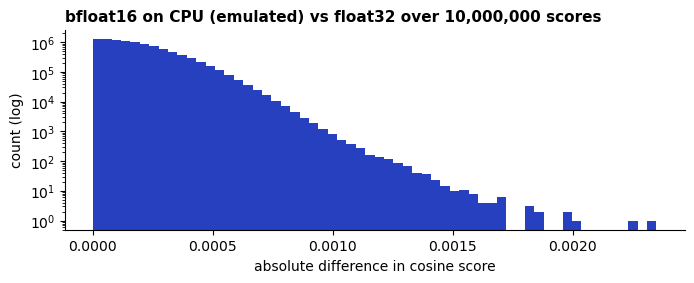

mean error 0.0002   max error 0.0023
top-10 neighbors identical on average: 100%    nearest neighbor identical: 100%
time: NumPy float32 88.4 ms    bfloat16 on CPU (emulated) 79.6 ms   (emulation is slower than float32 because of the conversions; ignore this number)


In [8]:
rng = np.random.default_rng(0)
sample = rng.choice(len(WORDS), 200, replace=False)
Q = V[sample]

t0 = time.perf_counter(); exact = Q @ V.T;            t_cpu = time.perf_counter() - t0
npu_used = STATE["use_npu"] and NPU["ok"]
if npu_used or BF16 is not None:
    t0 = time.perf_counter()
    approx = dots(Q, V_W) if npu_used else bf16_on_cpu(Q, V)
    t_alt = time.perf_counter() - t0
    label = "Q.ANT NPU" if npu_used else "bfloat16 on CPU (emulated)"

    err = np.abs(approx - exact)
    top = lambda S: np.argsort(-S, axis=1)[:, 1:11]            # column 0 is the word itself
    a, b = top(exact), top(approx)
    overlap = np.mean([len(set(x) & set(y)) / 10 for x, y in zip(a, b)])
    same_first = np.mean(a[:, 0] == b[:, 0])

    fig, ax = plt.subplots(figsize=(8, 2.6))
    ax.hist(err.ravel(), bins=60, color=ACCENT, log=True)
    ax.set_xlabel("absolute difference in cosine score"); ax.set_ylabel("count (log)")
    ax.set_title(f"{label} vs float32 over {err.size:,} scores")
    plt.show()
    print(f"mean error {err.mean():.4f}   max error {err.max():.4f}")
    print(f"top-10 neighbors identical on average: {overlap:.0%}    nearest neighbor identical: {same_first:.0%}")
    print(f"time: NumPy float32 {t_cpu * 1000:.1f} ms    {label} {t_alt * 1000:.1f} ms"
          + ("" if npu_used else "   (emulation is slower than float32 because of the conversions; ignore this number)"))
else:
    print("Install ml_dtypes (pip install ml_dtypes) to run this check.")

### The toolbox: one wrapper per toolkit function

Each wrapper below calls one toolkit function on the NPU and has an equivalent NumPy version. If an NPU call fails for any reason, you get one note and that call runs on the CPU.

| Wrapper | Toolkit function | Used in |
|---|---|---|
| `dots` | `native.linear_fprop`, `linear_fprop_preloaded_weights` | everywhere |
| `softmax`, `sigmoid`, `relu` | `ai.softmax_fprop`, `sigmoid_fprop`, `relu_fprop` | section 5 |
| `add_bias` | `ai.add_bias_fprop` | PCA in section 0 |
| `mul` | `native.mul_elementwise` | section 8 |
| `batchnorm` | `ai.batchnorm2d_fprop` | section 9 |
| `npu_meter` | `info.reset_perf_counter`, `get_perf_counter`, `get_sensor_info` | device panel |

In [9]:
def run_op(name, on_device, on_host):
    """Try the NPU version first, fall back to NumPy if there is no NPU or the call fails."""
    if on_npu():
        try:
            return np.asarray(on_device(), dtype=np.float32)
        except Exception as e:
            warn_once(name, f"{name} failed on the NPU ({type(e).__name__}: {e}); using NumPy.")
    return on_host()


def softmax(x, temperature=1.0):
    """Scores -> probabilities that add up to 1. A higher temperature makes the best score dominate."""
    x = np.asarray(x, dtype=np.float32).reshape(1, -1) * temperature     # softmax_fprop wants a first dimension of 1
    def host():
        e = np.exp(x - x.max())
        return e / e.sum()
    return run_op("softmax", lambda: qai.softmax_fprop(to_bf16(x)), host).reshape(-1)


def sigmoid(x):
    x = np.asarray(x, dtype=np.float32)
    return run_op("sigmoid", lambda: qai.sigmoid_fprop(to_bf16(x)), lambda: 1 / (1 + np.exp(-x))).reshape(x.shape)


def relu(x):
    x = np.asarray(x, dtype=np.float32)
    return run_op("relu", lambda: qai.relu_fprop(to_bf16(x)), lambda: np.maximum(x, 0)).reshape(x.shape)


def add_bias(X, bias):
    """X (n, channels) + bias (channels,)."""
    X, bias = np.asarray(X, dtype=np.float32), np.asarray(bias, dtype=np.float32)
    return run_op("add_bias", lambda: qai.add_bias_fprop(to_bf16(X), to_bf16(bias)), lambda: X + bias).reshape(X.shape)


def mul(a, b):
    """Element-wise product of two arrays with the same shape."""
    a, b = np.asarray(a, dtype=np.float32), np.asarray(b, dtype=np.float32)
    return run_op("mul", lambda: qnative.mul_elementwise(to_bf16(a), to_bf16(b)), lambda: a * b).reshape(a.shape)


def batchnorm(X, means, variances, gamma, beta, eps=1e-5):
    """Normalize every column of X (n, channels): gamma * (x - mean) / sqrt(var + eps) + beta."""
    X = np.asarray(X, dtype=np.float32)
    F = np.ascontiguousarray(X.T[:, :, None])                              # batchnorm2d wants (channels, height, width)
    arrays = [np.asarray(a, dtype=np.float32) for a in (means, variances, gamma, beta)]
    def host():
        m, v, g, b = (a[:, None, None] for a in arrays)
        return g * (F - m) / np.sqrt(v + eps) + b
    out = run_op("batchnorm", lambda: qai.batchnorm2d_fprop(to_bf16(F), *[to_bf16(a) for a in arrays], eps), host)
    return out.reshape(F.shape)[:, :, 0].T


class npu_meter:
    """Context manager: time a block and, on an NPU, report its busy/idle counters and sensors."""
    def __init__(self, label):
        self.label = label

    def __enter__(self):
        if on_npu():
            try:
                qinfo.reset_perf_counter(DEVICE_ID)
            except Exception:
                pass
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        wall = (time.perf_counter() - self.t0) * 1000
        line = f"{self.label}: {wall:.1f} ms"
        if on_npu():
            try:
                c = qinfo.get_perf_counter(DEVICE_ID)
                total, idle = c["timebased_counter"], c["stalling_counter"]
                line += f"   | NPU counter {total * 1000:.1f} ms, idle {idle * 1000:.1f} ms ({1 - idle / max(total, 1e-9):.0%} busy)"
            except Exception as e:
                line += f"   | counters unavailable ({e})"
            try:
                line += f"   | sensors {qinfo.get_sensor_info(DEVICE_ID)}"
            except Exception:
                pass
        print(line)
        return False

### Device panel: busy time, idle time, temperature

`npu_meter` wraps a block of work. It resets the performance counter, runs your code, then reads `timebased_counter` (seconds since the reset) and `stalling_counter` (seconds spent idle).

Below, the same 200 queries run two ways. One call sends all queries together. The other makes 200 separate calls. On an NPU the second way usually shows more idle time, because every call has a fixed cost. That is why the notebook batches work wherever it can.

In [10]:
queries = V[np.random.default_rng(1).choice(len(V), 200, replace=False)]

with npu_meter("200 queries, one call"):
    dots(queries, V_W)
with npu_meter("200 queries, one call each"):
    for q in queries:
        dots(q, V_W)

200 queries, one call: 44.8 ms
200 queries, one call each: 440.6 ms


## 0. The map: words become coordinates

These 40 words come from five topics. The colors are labels added for reference; the positions come only from the vectors, flattened from 100 dimensions to 2 with PCA.

Pick a word in **Focus**. The dashed lines go to its three closest words measured in all 100 dimensions. They are not always the ones that look closest on the flat map.

In [11]:
GROUPS = {
    "Animals":   "cat dog horse rabbit tiger wolf sheep fox",
    "Food":      "bread cheese rice pasta soup banana chocolate butter",
    "Countries": "france germany japan brazil kenya canada mexico india",
    "Music":     "guitar piano violin drums jazz opera melody song",
    "Feelings":  "happy sad angry joy fear proud lonely afraid",
}
hero_words = [w for ws in GROUPS.values() for w in ws.split()]
hero_group = [g for g, ws in GROUPS.items() for _ in ws.split()]
HX = np.array([vec(w) for w in hero_words])
hero_xy, hero_kept = pca_2d(HX)


def draw_map(focus):
    i = hero_words.index(focus)
    sims = dots(HX[i], HX)[0]
    neighbors = [j for j in np.argsort(-sims) if j != i][:3]

    fig, ax = plt.subplots(figsize=(10, 6.2))
    for j in neighbors:
        ax.plot(*zip(hero_xy[i], hero_xy[j]), "--", color=ACCENT, lw=1.4, zorder=1)
    for g, color in zip(GROUPS, GROUP_COLORS):
        idx = [k for k, gg in enumerate(hero_group) if gg == g]
        ax.scatter(hero_xy[idx, 0], hero_xy[idx, 1], s=45, color=color, label=g, zorder=2)
    ax.scatter(*hero_xy[i], s=160, facecolor="none", edgecolor=INK, lw=2, zorder=3)
    for k, w in enumerate(hero_words):
        strong = k == i or k in neighbors
        ax.annotate(w, hero_xy[k], xytext=(5, 3), textcoords="offset points", fontsize=9,
                    color=INK if strong else MUTED, fontweight="bold" if strong else "normal")
    ax.set_title(f"40 words in 2D (PCA keeps {hero_kept:.0%} of the variance)")
    ax.legend(loc="best", frameon=False, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    plt.show()
    print(f"{focus}: closest of these 40 in 100 dimensions -> "
          + ", ".join(f"{hero_words[j]} {sims[j]:.2f}" for j in neighbors))


widgets.interact(draw_map, focus=widgets.Dropdown(options=hero_words, value="jazz", description="Focus"));

interactive(children=(Dropdown(description='Focus', index=28, options=('cat', 'dog', 'horse', 'rabbit', 'tiger…

## 1. A word is a list of numbers

No single number means "animal" or "past tense"; meaning is spread across all 100. Each row below is one word's vector, one cell per number: **orange is positive, teal is negative**.

Compare `cat` with `dog`, then with `car`, and look for repeated patterns. Then try your own words.

In [12]:
def draw_barcodes(word1, word2, word3):
    words = [clean(w) for w in (word1, word2, word3)]
    if missing(*words):
        return
    M = np.array([vec(w) for w in words])
    limit = np.abs(M).max()

    fig, ax = plt.subplots(figsize=(11, 2.3))
    im = ax.imshow(M, aspect="auto", cmap=DIVERGING, vmin=-limit, vmax=limit, interpolation="nearest")
    ax.set_yticks(range(len(words)), words)
    ax.set_xlabel("dimension (1 to 100)")
    ax.spines[:].set_visible(False)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
    plt.show()

    for w in words:
        print(f"{w:>10}: {np.round(vec(w)[:5], 3)} ... (100 numbers, length {np.linalg.norm(vec(w)):.2f})")
    print()
    for a, b in combinations(words, 2):
        print(f"cosine({a}, {b}) = {vec(a) @ vec(b):.2f}")


w1, w2, w3 = text_box("cat"), text_box("dog"), text_box("car")
display(row(w1, w2, w3), widgets.interactive_output(draw_barcodes, {"word1": w1, "word2": w2, "word3": w3}))

Output()

## 2. Similarity is an angle

To compare two vectors, measure the angle between them. Cosine similarity is **1** when they point the same way, **0** at a right angle and **−1** when they point opposite ways.

$$\cos\theta = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

Length drops out of the formula. Move the **b length** slider: the dot product changes, the cosine does not. The same formula works in 100 dimensions; you just can't draw it.

In [13]:
def cosine(a, b):
    """Cosine similarity, written out: dot product divided by both lengths."""
    dot = np.sum(a * b)
    return float(dot / (np.linalg.norm(a) * np.linalg.norm(b)))


def draw_angle(a_angle, a_length, b_angle, b_length):
    a = a_length * np.array([np.cos(np.radians(a_angle)), np.sin(np.radians(a_angle))])
    b = b_length * np.array([np.cos(np.radians(b_angle)), np.sin(np.radians(b_angle))])
    cos = cosine(a, b)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls=":", color=MUTED))
    ax.axhline(0, color="#ccd3cb", lw=1); ax.axvline(0, color="#ccd3cb", lw=1)
    for v, name, color in [(a, "a", ACCENT), (b, "b", POS)]:
        ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
        ax.text(*(v * 1.12), name, color=color, fontsize=14, fontweight="bold", ha="center", va="center")
    start, end = sorted([a_angle, b_angle])
    if end - start > 180:
        start, end = end, start + 360
    arc = np.radians(np.linspace(start, end, 50))
    ax.plot(0.3 * np.cos(arc), 0.3 * np.sin(arc), color=MUTED)
    ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.45, 1.45); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"cos θ = {cos:.3f}")
    plt.show()
    print(f"a = ({a[0]:.2f}, {a[1]:.2f})   |a| = {np.linalg.norm(a):.2f}")
    print(f"b = ({b[0]:.2f}, {b[1]:.2f})   |b| = {np.linalg.norm(b):.2f}")
    print(f"a · b = {a @ b:.3f}")
    print(f"angle = {np.degrees(np.arccos(np.clip(cos, -1, 1))):.1f}°   cos θ = {cos:.3f}")


slider = lambda v, lo, hi, step, d: widgets.FloatSlider(value=v, min=lo, max=hi, step=step, description=d,
                                                       continuous_update=True, readout_format=".2f")
angle_controls = {
    "a_angle": slider(17, 0, 360, 1, "a angle"), "a_length": slider(0.96, 0.1, 1.3, 0.01, "a length"),
    "b_angle": slider(65, 0, 360, 1, "b angle"), "b_length": slider(0.90, 0.1, 1.3, 0.01, "b length"),
}
c = angle_controls
display(widgets.HBox([widgets.VBox([c["a_angle"], c["a_length"]]), widgets.VBox([c["b_angle"], c["b_length"]])]),
        widgets.interactive_output(draw_angle, angle_controls))

Output()

### Now with real words

Our vectors already have length 1, so the cosine is simply the dot product: 100 multiplications added up. Pick a pair or type your own.

In [14]:
def draw_pair(word_a, word_b):
    if missing(word_a, word_b):
        return
    s = cosine(vec(word_a), vec(word_b))
    fig, ax = plt.subplots(figsize=(8, 1.3))
    ax.imshow(np.linspace(-1, 1, 256)[None, :], extent=(-1, 1, 0, 1), cmap=DIVERGING, aspect="auto")
    ax.axvline(s, color=INK, lw=3)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1]); ax.set_yticks([])
    ax.spines[:].set_visible(False)
    ax.set_title(f"cosine({clean(word_a)}, {clean(word_b)}) = {s:.3f}", fontsize=13)
    plt.show()


PAIRS = ["coffee · tea", "cat · dog", "cat · car", "king · queen", "doctor · banana", "up · down"]
pa, pb = text_box("coffee"), text_box("tea")
pair_preset = widgets.Dropdown(options=PAIRS, value=PAIRS[0], description="Examples")

def use_pair(change):
    pa.value, pb.value = change["new"].split(" · ")

pair_preset.observe(use_pair, names="value")
display(row(pa, widgets.Label(" · "), pb, pair_preset),
        widgets.interactive_output(draw_pair, {"word_a": pa, "word_b": pb}))

Output()

## 3. Meaning has neighborhoods

Semantic search is this exercise at scale: score every stored vector against the query and keep the best. Here that means 50,000 dot products, which takes a few milliseconds. Vector databases do the same over millions of items with approximate indexes such as HNSW.

**Click any result button to move there and keep walking.** Your path builds up underneath.

In [15]:
def nearest(v, k=10, exclude=()):
    """The k words whose vectors point most nearly the same way as v."""
    v = v / np.linalg.norm(v)
    scores = dots(v, V_W)[0]                         # one dot product per word, on the NPU if available
    skip = {INDEX[clean(w)] for w in exclude if clean(w) in INDEX}
    results = []
    for i in np.argsort(-scores):
        if i not in skip:
            results.append((WORDS[i], float(scores[i])))
            if len(results) == k:
                break
    return results


def draw_neighbors(word, k=10):
    if missing(word):
        return []
    t0 = time.perf_counter()
    results = nearest(vec(word), k, exclude=[word])
    ms = (time.perf_counter() - t0) * 1000
    names, scores = zip(*results)
    fig, ax = plt.subplots(figsize=(8, 0.32 * k + 0.8))
    ax.barh(range(k), scores, color=ACCENT)
    ax.set_yticks(range(k), names); ax.invert_yaxis()
    for i, s in enumerate(scores):
        ax.text(s + 0.01, i, f"{s:.2f}", va="center", fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.set_title(f"Closest to '{clean(word)}'  (scored {len(WORDS):,} vectors in {ms:.1f} ms on {'NPU' if STATE['use_npu'] and NPU['ok'] else 'CPU'})")
    plt.show()
    return names


nn_word = text_box("coffee", width="200px")
nn_k = widgets.IntSlider(value=10, min=5, max=20, description="Results")
nn_out, nn_buttons, nn_trail = widgets.Output(), widgets.HBox(layout=widgets.Layout(flex_flow="row wrap")), widgets.HTML()
trail, walking = [], [False]


def walk(word):
    walking[0] = True
    trail.append(word)
    nn_word.value = word
    walking[0] = False


def nn_update(change=None):
    word = clean(nn_word.value)
    if not walking[0]:
        trail[:] = [word]
    with nn_out:
        clear_output(wait=True)
        names = draw_neighbors(word, nn_k.value)
    buttons = []
    for name in names:
        b = widgets.Button(description=name, layout=widgets.Layout(width="auto"))
        b.on_click(lambda _, n=name: walk(n))
        buttons.append(b)
    nn_buttons.children = buttons
    nn_trail.value = "<b>Your path:</b> " + " → ".join(trail[-12:]) if len(trail) > 1 else ""


nn_word.observe(nn_update, names="value")
nn_k.observe(nn_update, names="value")
display(row(nn_word, nn_k), nn_out, widgets.Label("Walk to:"), nn_buttons, nn_trail)
nn_update()

Output()

Label(value='Walk to:')

HBox(layout=Layout(flex_flow='row wrap'))

HTML(value='')

## 4. Directions carry meaning

The difference between two vectors can capture a relationship. `king − man` leaves roughly "royalty without the man". Add `woman` and you land next to `queen`.

The left plot is a flat slice through your three words. Both blue arrows are the same offset. The orange dot is the real word nearest to where the second arrow ends; the gap between them shows how far the analogy misses.

Results normally leave out the three input words. Untick the box to see why: for the first example, `king` itself comes out on top.

In [16]:
def analogy(a, b, c, k=6, exclude_inputs=True):
    """a - b + c: 'a is to b as ? is to c'."""
    target = vec(a) - vec(b) + vec(c)
    return nearest(target, k, exclude=(a, b, c) if exclude_inputs else ())


def draw_analogy(a, b, c, leave_out_inputs=True):
    a, b, c = clean(a), clean(b), clean(c)
    if missing(a, b, c):
        return
    if a == b:
        print("The first two words must differ.")
        return
    results = analogy(a, b, c, exclude_inputs=leave_out_inputs)
    A, B, C, R = vec(a), vec(b), vec(c), vec(results[0][0])

    # A flat slice through b, a and c: x points from b to a, y points toward c.
    x_axis = (A - B) / np.linalg.norm(A - B)
    c_off = C - B
    y_vec = c_off - (c_off @ x_axis) * x_axis
    y_axis = y_vec / max(np.linalg.norm(y_vec), 1e-9)
    flat = lambda v: np.array([(v - B) @ x_axis, (v - B) @ y_axis])
    pb, pa, pc, pr = flat(B), flat(A), flat(C), flat(R)
    pt = pc + (pa - pb)                                   # exactly c + (a - b)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 2]})
    ax1.plot(*zip(pb, pc), ":", color=MUTED); ax1.plot(*zip(pa, pt), ":", color=MUTED)
    ax1.plot(*zip(pt, pr), ":", color=POS)
    ax1.annotate("", xy=pa, xytext=pb, arrowprops=dict(arrowstyle="-|>", color=ACCENT, lw=2.5))
    ax1.annotate("", xy=pt, xytext=pc, arrowprops=dict(arrowstyle="-|>", color=ACCENT, lw=2.5, ls="--"))
    ax1.scatter(*np.array([pb, pa, pc]).T, color=INK, zorder=3)
    ax1.scatter(*pt, s=80, facecolor="white", edgecolor=ACCENT, lw=2, zorder=3)
    ax1.scatter(*pr, s=60, color=POS, zorder=3)
    label = lambda p, t, color, dy: ax1.annotate(t, p, xytext=(0, dy), textcoords="offset points",
                                                 ha="center", va="center", color=color, fontsize=10)
    label(pb, b, INK, -14); label(pa, a, INK, -14); label(pc, c, INK, 14)
    r_below = pr[1] < pt[1]
    label(pt, f"{c} + ({a} − {b})", ACCENT, 14 if r_below else -14)
    label(pr, results[0][0], POS, -14 if r_below else 14)
    ax1.set_aspect("equal"); ax1.margins(0.25); ax1.axis("off")
    ax1.set_title(f"{a} − {b} + {c}")

    names, scores = zip(*results)
    ax2.barh(range(len(names)), scores, color=[MUTED if n in (a, b, c) else ACCENT for n in names])
    ax2.set_yticks(range(len(names)), [n + (" (input)" if n in (a, b, c) else "") for n in names])
    ax2.invert_yaxis(); ax2.set_xlim(0, 1)
    for i, s in enumerate(scores):
        ax2.text(s + 0.01, i, f"{s:.2f}", va="center", fontsize=9)
    ax2.set_title("Nearest words to the result")
    plt.tight_layout()
    plt.show()


ANALOGIES = ["king − man + woman", "paris − france + italy", "actor − man + woman",
             "walking − walk + swim", "beijing − china + russia", "went − go + see"]
aa, ab, ac = text_box("king"), text_box("man"), text_box("woman")
ana_leave_out = widgets.Checkbox(value=True, description="Leave out the three input words", indent=False)
ana_preset = widgets.Dropdown(options=ANALOGIES, value=ANALOGIES[0], description="Examples")

def use_analogy(change):
    first, rest = change["new"].split(" − ")
    second, third = rest.split(" + ")
    aa.value, ab.value, ac.value = first, second, third

ana_preset.observe(use_analogy, names="value")
display(row(aa, widgets.Label(" − "), ab, widgets.Label(" + "), ac), row(ana_preset, ana_leave_out),
        widgets.interactive_output(draw_analogy, {"a": aa, "b": ab, "c": ac, "leave_out_inputs": ana_leave_out}))

Output()

## 5. From words to sentences

The quickest way to embed a sentence is to average its word vectors. Two adjustments make that average far more useful (Arora, Liang and Ma, 2017):

1. **Weight by rarity.** Frequent words like *the* and *is* say little, so their weight drops close to 0. The top chart shows each word's weight.
2. **Remove the common direction.** Every average leans toward the center of the whole vocabulary, which squeezes all scores together. Subtracting that shared direction spreads them out. Toggle it and watch the score range.

Search the 24 notes below. The **Score view** menu changes how scores are shown: raw cosine, **softmax** (probabilities that add up to 1; the slider sets how sharply the best match wins), **sigmoid** (each score squashed to 0 to 1 around the average) or **ReLU** (only scores above average survive). These run on the NPU's softmax, sigmoid and ReLU layers. The best matches often share **no words** with your query, which keyword search could never find.

In [17]:
WEIGHT_A = 1e-3
ZIPF_TOTAL = np.log(400_000) + 0.5772          # turns a frequency rank into a probability
COMMON = V.mean(axis=0) / np.linalg.norm(V.mean(axis=0))


def tokenize(text):
    return re.findall(r"[a-z]+", text.lower().replace("n't", " not"))


def word_weight(word):
    """Close to 1 for rare words, close to 0 for very common ones."""
    frequency = 1 / (RANKS[INDEX[word]] * ZIPF_TOTAL)
    return WEIGHT_A / (WEIGHT_A + frequency)


def embed(text, remove_common=True):
    """Sentence vector: rarity-weighted average of word vectors, minus the common direction."""
    tokens = [t for t in tokenize(text) if t in INDEX]
    if not tokens:
        return None
    v = sum(word_weight(t) * V[INDEX[t]] for t in tokens)
    if remove_common:
        v = v - (v @ COMMON) * COMMON
    return v / np.linalg.norm(v)


NOTES = [
    "Restart the router if the wifi keeps dropping.",
    "A cracked phone screen can usually be replaced in an hour.",
    "Back up your laptop before installing a system update.",
    "Booking flights on a weekday is often cheaper.",
    "Pack light layers for mountain hikes since temperatures change fast.",
    "Exchange some cash before you arrive at the airport.",
    "Simmer the beans slowly with garlic and onion.",
    "Ripe bananas make the sweetest bread.",
    "Toast the rice before adding broth for a fluffier pilaf.",
    "Puppies need several small meals a day.",
    "Take your cat to the vet if it stops eating.",
    "Walk the dog twice a day to keep it calm.",
    "Put a fixed share of each paycheck into savings.",
    "Credit card interest grows quickly if you only pay the minimum.",
    "Compare insurance quotes before renewing your policy.",
    "Drink water regularly during long runs.",
    "Stretch after training to ease sore muscles.",
    "Sleep matters as much as exercise for recovery.",
    "Heavy rain is expected tomorrow afternoon.",
    "Bring a jacket because the evening will be chilly.",
    "The museum offers free entry on the first Sunday of the month.",
    "The concert starts at eight and doors open an hour earlier.",
    "Water tomato plants early in the morning.",
    "Repot houseplants when roots grow out of the bottom.",
]


PROJECT = (np.eye(V.shape[1]) - np.outer(COMMON, COMMON)).astype(np.float32)    # "remove the common direction" as a matrix


def embed_batch(texts, remove_common=True):
    """Embed many texts at once, one row each.

    The weighted sum of word vectors is a linear layer: a (texts x words) matrix of weights times the word vectors.
    So it runs on the NPU when one is available. Removing the common direction is also a matrix product."""
    tokens = [[t for t in tokenize(x) if t in INDEX] for x in texts]
    vocab = sorted({t for ts in tokens for t in ts})
    if not vocab:
        return np.zeros((len(texts), V.shape[1]), dtype=np.float32)
    column = {t: j for j, t in enumerate(vocab)}
    A = np.zeros((len(texts), len(vocab)), dtype=np.float32)
    for r, ts in enumerate(tokens):
        for t in ts:
            A[r, column[t]] += word_weight(t)
    local = V[[INDEX[t] for t in vocab]]                  # (words used, 100)
    E = dots(A, local.T)                                  # features = A, weights = local.T of shape (100, words used)
    if remove_common:
        E = dots(E, PROJECT)                              # v - (v . c) c as a 100 x 100 matrix product
    return E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-9)


_DOC_CACHE = {}


def embed_matrix(docs, remove_common=True):
    """One row per document. Computed once per list of documents, then reused."""
    key = (tuple(docs), remove_common)
    if key not in _DOC_CACHE:
        _DOC_CACHE[key] = embed_batch(docs, remove_common)
    return _DOC_CACHE[key]


def search(query, docs=NOTES, remove_common=True):
    """All docs sorted by similarity to the query: [(score, doc), ...]. The scoring runs on the NPU if available."""
    q = embed(query, remove_common)
    if q is None:
        return []
    scores = dots(q, embed_matrix(docs, remove_common))[0]
    return sorted(zip(map(float, scores), docs), reverse=True)


def transform(scores, view, temperature):
    """Show raw cosine scores, or pass them through a toolkit layer."""
    s = np.asarray(scores, dtype=np.float32)
    if view == "softmax":
        return softmax(s, temperature)                    # ai.softmax_fprop
    if view == "sigmoid":
        return sigmoid((s - s.mean()) * temperature)      # ai.sigmoid_fprop
    if view == "relu":
        return relu(s - s.mean())                         # ai.relu_fprop
    return s


def draw_search(query, remove_common=True, show=8, view="cosine", temperature=20.0):
    tokens = tokenize(query)
    ranked = search(query, remove_common=remove_common)
    if not ranked:
        print("None of these words are in the vocabulary.")
        return
    content = {t for t in tokens if t in INDEX and word_weight(t) > 0.5}
    raw = np.array([s for s, _ in ranked])
    shown = transform(raw, view, temperature)

    fig = plt.figure(figsize=(11, 6.5))
    grid = fig.add_gridspec(2, 1, height_ratios=[1, 3.3], hspace=0.5)
    ax0 = fig.add_subplot(grid[0])
    weights = [word_weight(t) if t in INDEX else 0 for t in tokens]
    ax0.bar(range(len(tokens)), weights, color=[POS if t in INDEX else "#cccccc" for t in tokens])
    ax0.set_xticks(range(len(tokens)), [t if t in INDEX else f"{t} (unknown)" for t in tokens])
    ax0.set_ylim(0, 1.05); ax0.set_title("How the query is read: weight of each word")

    ax1 = fig.add_subplot(grid[1])
    top = ranked[:show]
    ax1.barh(range(len(top)), shown[:show], color=[ACCENT if i < 3 else MUTED for i in range(len(top))])
    ax1.set_yticks(range(len(top)), [d for _, d in top]); ax1.invert_yaxis()
    hi = 1.35 if view == "cosine" else max(float(shown.max()), 1e-3) * 1.7
    for i, (s, d) in enumerate(top):
        shared = content & set(tokenize(d))
        note = "shares: " + ", ".join(sorted(shared)) if shared else "no words in common"
        value = f"{shown[i]:.2f}" if view == "cosine" else f"{shown[i]:.2f} (cos {s:.2f})"
        ax1.text(max(float(shown[i]), 0) + 0.01 * hi, i, f"{value}   {note}", va="center", fontsize=9,
                 color=INK if shared else "#1D8463")
    ax1.set_xlim(min(0, float(shown.min())), hi)
    ax1.set_title(f"Top {show} of {len(NOTES)} notes   (score view: {view})")
    plt.show()
    if view == "softmax":
        print(f"Probabilities across all {len(NOTES)} notes add up to {shown.sum():.2f}; the top match holds {shown[0]:.0%}.")
    else:
        print(f"Scores run from {raw[-1]:.2f} to {raw[0]:.2f} across all {len(NOTES)} notes.")


QUERIES = ["my kitten will not eat", "cheap tickets to travel abroad", "how can i spend less money",
           "will it be sunny this weekend", "my legs ache after jogging",
           "growing vegetables in the garden", "what should i wear tonight"]
sq = text_box("my kitten will not eat", width="360px")
sq_preset = widgets.Dropdown(options=QUERIES, value=QUERIES[0], description="Examples",
                             layout=widgets.Layout(width="360px"))
sq_rm = widgets.Checkbox(value=True, description="Subtract the common direction", indent=False)
sq_view = widgets.Dropdown(options=["cosine", "softmax", "sigmoid", "relu"], value="cosine", description="Score view")
sq_temp = widgets.FloatSlider(value=20, min=1, max=80, step=1, description="Sharpness", readout_format=".0f")
sq_preset.observe(lambda change: setattr(sq, "value", change["new"]), names="value")
display(row(sq, sq_preset), row(sq_rm, sq_view, sq_temp),
        widgets.interactive_output(draw_search, {"query": sq, "remove_common": sq_rm,
                                                 "view": sq_view, "temperature": sq_temp}))

Output()

### 5b. The same embeddings, computed by the NPU

Above, `embed()` handles one sentence at a time on the CPU. `embed_batch()` handles many at once, and the search uses it. A sentence vector is a weighted sum of word vectors, which is a matrix product, so `linear_fprop` can compute it. The check below compares the two over all 24 notes. Small differences are bfloat16 rounding.

In [18]:
with npu_meter("embed 24 notes, one at a time (CPU)"):
    one_by_one = np.array([embed(d) for d in NOTES])
with npu_meter("embed 24 notes, one batch (linear layer)"):
    batch = embed_batch(NOTES)

agreement = np.sum(one_by_one * batch, axis=1)           # cosine between the two versions of each note
print(f"The two versions of each note point the same way: lowest cosine {agreement.min():.4f}")
print(f"Largest difference in any single number: {np.abs(one_by_one - batch).max():.4f}")

embed 24 notes, one at a time (CPU): 2.4 ms
embed 24 notes, one batch (linear layer): 2.2 ms
The two versions of each note point the same way: lowest cosine 1.0000
Largest difference in any single number: 0.0000


## 6. Where word averages fail

Averaging throws away word order and context. Every number below is computed live from the same vectors.

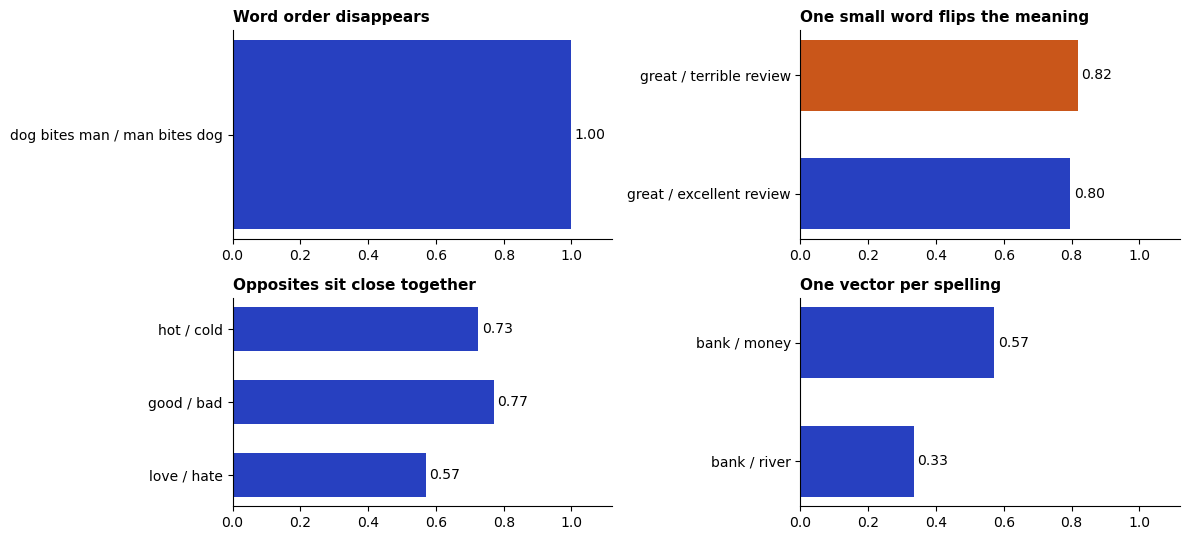

Word order:   both sentences hold the same three words, so their averages are identical.
Small words:  swapping one word keeps the rest of the sentence, so the opposite review can score
              as high as a paraphrase.
Opposites:    antonyms appear in the same contexts. Similar here means related, not interchangeable.
Spelling:     apple's neighbors are microsoft, ibm, intel, software - the fruit loses.
Unknown:       'chatbot' has no vector, 'selfie' has no vector, 'embeddings' has no vector
Flat maps:    the map in section 0 keeps only 30% of the variance.


In [19]:
S = lambda a, b: float(embed(a) @ embed(b))      # sentence similarity
W = lambda a, b: float(vec(a) @ vec(b))          # word similarity

panels = [
    ("Word order disappears", [("dog bites man / man bites dog", S("dog bites man", "man bites dog"))]),
    ("One small word flips the meaning", [
        ("great / terrible review", S("the movie was great", "the movie was terrible")),
        ("great / excellent review", S("the movie was great", "the film was excellent"))]),
    ("Opposites sit close together", [("hot / cold", W("hot", "cold")), ("good / bad", W("good", "bad")),
                                      ("love / hate", W("love", "hate"))]),
    ("One vector per spelling", [("bank / money", W("bank", "money")), ("bank / river", W("bank", "river"))]),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 5.5))
for ax, (title, rows) in zip(axes.flat, panels):
    labels, scores = zip(*rows)
    ax.barh(range(len(rows)), scores, height=0.6, color=[POS if "terrible" in l else ACCENT for l in labels])
    ax.set_yticks(range(len(rows)), labels); ax.invert_yaxis(); ax.set_xlim(0, 1.12)
    for i, s in enumerate(scores):
        ax.text(s + 0.01, i, f"{s:.2f}", va="center")
    ax.set_title(title)
plt.tight_layout()
plt.show()

print("Word order:   both sentences hold the same three words, so their averages are identical.")
print("Small words:  swapping one word keeps the rest of the sentence, so the opposite review can score")
print("              as high as a paraphrase.")
print("Opposites:    antonyms appear in the same contexts. Similar here means related, not interchangeable.")
print("Spelling:     apple's neighbors are", ", ".join(w for w, _ in nearest(vec("apple"), 4, ["apple"])),
      "- the fruit loses.")
print("Unknown:      ", ", ".join(f"'{w}' {'found' if w in INDEX else 'has no vector'}"
                               for w in ["chatbot", "selfie", "embeddings"]))
print(f"Flat maps:    the map in section 0 keeps only {hero_kept:.0%} of the variance.")

### Test a limit yourself

Type two sentences and compare them. Try reversing word order, adding *not*, or swapping a word for its opposite.

In [20]:
def compare(sentence_a, sentence_b, remove_common=True):
    ea, eb = embed(sentence_a, remove_common), embed(sentence_b, remove_common)
    if ea is None or eb is None:
        print("Each sentence needs at least one known word.")
        return
    s = float(ea @ eb)
    shared = set(tokenize(sentence_a)) & set(tokenize(sentence_b))
    print(f"similarity = {s:.3f}   " + "#" * int(round(max(s, 0) * 30)))
    print("shared words:", ", ".join(sorted(shared)) if shared else "none")


ca = text_box("i love this movie", width="320px")
cb = text_box("i do not love this movie", width="320px")
cmp_rm = widgets.Checkbox(value=True, description="Subtract the common direction", indent=False)
display(row(ca, cb), cmp_rm,
        widgets.interactive_output(compare, {"sentence_a": ca, "sentence_b": cb, "remove_common": cmp_rm}))

Checkbox(value=True, description='Subtract the common direction', indent=False)

Output()

Transformer embedding models fix most of these by reading the whole sentence at once, so order, negation and context all change the vector. The tools stay the same: cosine similarity, nearest neighbors, projections and clustering work on their output exactly as they do here. The bonus at the end compares the two.

## 7. Search the Q.ANT toolkit itself

Same method, new documents: one plain-English line per toolkit function. Ask for what you want to do and see which function the embeddings point to. The words are matched by meaning, so *\"shrink an image\"* can find pooling without containing the word.

Technical words missing from the GloVe vocabulary (such as `bfloat16`) are skipped, so descriptions are written in everyday words. This is the limit from section 6 again: vocabulary and context matter.

In [21]:
TOOLKIT = {
    "generic.upload":                "copy a matrix from the computer into the memory of the device so it can be reused",
    "generic.download":              "copy results back from the memory of the device to the computer, download the matrix",
    "generic.allocate":              "reserve an empty block of memory on the device for a matrix of a given size",
    "generic.get_available_npus":    "list every processing unit connected to this machine with its serial number",
    "generic.init_npu":              "start up a processing unit before use",
    "generic.release_npu":           "free a processing unit so a different program can use it",
    "native.linear_fprop":           "multiply input features by a weight matrix, a fully connected layer",
    "native.linear_fprop_preloaded_weights": "multiply features by weights that already sit on the device, avoiding repeated copying",
    "native.mul_elementwise":        "multiply two arrays of the same shape number by number",
    "native.calc_scaled_periodic_nl_fprop": "apply a smooth repeating wave shaped nonlinearity to every pair of inputs and weights",
    "ai.conv_fprop":                 "slide a small filter over an image to detect patterns, a convolution layer",
    "ai.conv_transpose_fprop":       "enlarge an image with a learned filter, an upsampling transposed convolution",
    "ai.maxpool2d_fprop":            "shrink an image by keeping the largest value in each window",
    "ai.avgpool2d_fprop":            "shrink an image by averaging the values in each window",
    "ai.batchnorm2d_fprop":          "normalize image channels using stored mean and variance, then scale and shift",
    "ai.add_bias_fprop":             "add a constant offset to every channel of the features",
    "ai.relu_fprop":                 "remove negative values by setting every negative number to zero, a rectifier activation",
    "ai.sigmoid_fprop":              "squash every number smoothly into the range between zero and one",
    "ai.softmax_fprop":              "turn a list of scores into probabilities that add up to one",
    "ai.calc_kan_layer_fprop":       "a Kolmogorov Arnold network layer built from learned waves with phases and amplitudes",
    "info.get_sensor_info":          "read how hot the chip is, its temperature and other sensor values",
    "info.get_perf_counter":         "measure how much time the device spent working and how much sitting idle",
    "info.setup_logging":            "write log messages to the screen and to files in a folder",
    "utils.align_ndarray_page_boundary": "copy an array so its memory starts on an aligned boundary and avoid an extra copy later",
}
TK_NAMES, TK_TEXT = list(TOOLKIT), list(TOOLKIT.values())
TK_EXAMPLES = ["make a picture smaller", "turn scores into probabilities", "how hot is the chip",
               "keep my weights on the device", "copy data back from the chip", "remove negative values"]


def draw_toolkit_search(query, show=5):
    ranked = search(query, docs=TK_TEXT)
    if not ranked:
        print("None of these words are in the vocabulary.")
        return
    names = {t: n for n, t in TOOLKIT.items()}
    top = ranked[:show]
    fig, ax = plt.subplots(figsize=(10, 0.45 * show + 0.9))
    ax.barh(range(show), [s for s, _ in top], color=[ACCENT if i == 0 else MUTED for i in range(show)])
    ax.set_yticks(range(show), [names[t] for _, t in top]); ax.invert_yaxis()
    for i, (s, t) in enumerate(top):
        ax.text(max(s, 0) + 0.01, i, f"{s:.2f}", va="center", fontsize=9)
    ax.set_xlim(min(0, top[-1][0]), 1)
    ax.set_title(f"Toolkit functions closest to: {query}")
    plt.show()
    print(f"Best match: {names[top[0][1]]}\n  {top[0][1]}")


tk_q = text_box("make a picture smaller", width="360px")
tk_preset = widgets.Dropdown(options=TK_EXAMPLES, value=TK_EXAMPLES[0], description="Examples",
                             layout=widgets.Layout(width="360px"))
tk_preset.observe(lambda change: setattr(tk_q, "value", change["new"]), names="value")
display(row(tk_q, tk_preset), widgets.interactive_output(draw_toolkit_search, {"query": tk_q}))

Output()

## 8. Word order with a convolution and pooling

*Toolkit functions: `ai.upload_conv_weights`, `conv_fprop_preloaded_weights`, `avgpool2d_fprop`, `maxpool2d_fprop`, `native.mul_elementwise`.*

Section 6 showed that averaging forgets word order. A **convolution** looks at neighboring words together, so order can matter. Here each word is a column of 100 channels, and a kernel of width 2 turns every pair of neighbors into one new vector:

`pair(t) = word(t) + R · word(t+1)`

where `R` is a fixed rotation. Because `R` treats the second word differently from the first, swapping the words changes the result. Then a **pooling** layer squeezes all the pair vectors into one sentence vector: average pooling (mean) or max pooling (largest value per dimension).

Honest caveat: this kernel is not trained. It only shows that a convolution can make a sentence vector order-aware. Real models learn their kernels from data. The word weights from section 5 are applied with `mul_elementwise`.

In [22]:
R = np.linalg.qr(np.random.default_rng(7).standard_normal((V.shape[1], V.shape[1])))[0].astype(np.float32)
KERNEL = np.zeros((V.shape[1], V.shape[1], 1, 2), dtype=np.float32)    # (out channels, in channels, height, width)
KERNEL[:, :, 0, 0] = np.eye(V.shape[1])                                # first word of the pair: unchanged
KERNEL[:, :, 0, 1] = R                                                 # second word of the pair: rotated

KERNEL_HANDLE = None
if NPU["ok"]:
    try:
        KERNEL_HANDLE = qai.upload_conv_weights(to_bf16(KERNEL), DEVICE_ID)     # uploaded once, reused for every sentence
    except Exception as e:
        warn_once("conv_upload", f"could not upload the kernel ({e}); sending it with every call.")


def token_matrix(text):
    """(words, 100): word vectors, each scaled by its rarity weight with mul_elementwise."""
    tokens = [t for t in tokenize(text) if t in INDEX]
    if not tokens:
        return None
    X = V[[INDEX[t] for t in tokens]]
    w = np.array([word_weight(t) for t in tokens], dtype=np.float32)[:, None] * np.ones((1, V.shape[1]), dtype=np.float32)
    return mul(X, w)


def finish(v):
    v = np.asarray(v, dtype=np.float32).reshape(-1)
    v = v - (v @ COMMON) * COMMON
    return v / max(np.linalg.norm(v), 1e-9)


def pool(F, kind):
    """F: (channels, 1, positions). Pool every channel over all positions into one number."""
    width = F.shape[2]
    if kind == "avg":
        return run_op("avgpool", lambda: qai.avgpool2d_fprop(to_bf16(F), (1, width), 1, 0), lambda: F.mean(axis=2, keepdims=True))
    return run_op("maxpool", lambda: qai.maxpool2d_fprop(to_bf16(F), (1, width), 1, 0), lambda: F.max(axis=2, keepdims=True))


def embed_conv(text, kind="avg"):
    X = token_matrix(text)
    if X is None:
        return None
    if len(X) == 1:
        return finish(X[0])
    F = np.ascontiguousarray(X.T[:, None, :])                             # (100 channels, 1, words)
    def host():
        return (F[:, 0, :-1] + R @ F[:, 0, 1:])[:, None, :]
    def device():
        if KERNEL_HANDLE is not None:
            return qai.conv_fprop_preloaded_weights(to_bf16(F), KERNEL_HANDLE, 0, 1, 1)
        return qai.conv_fprop(to_bf16(F), to_bf16(KERNEL), 0, 1, 1, DEVICE_ID)
    pairs = run_op("conv", device, host)                                  # (100, 1, words - 1)
    return finish(pool(pairs, kind))


def embed_maxpool(text):
    X = token_matrix(text)
    return None if X is None else finish(pool(np.ascontiguousarray(X.T[:, None, :]), "max"))


METHODS = {"average (section 5)": embed,
           "max pooling only": embed_maxpool,
           "pairs + average": lambda t: embed_conv(t, "avg"),
           "pairs + max": lambda t: embed_conv(t, "max")}
ORDER_PAIRS = ["dog bites man · man bites dog", "i love this movie · i do not love this movie",
               "the movie was great · the movie was terrible", "the movie was great · the film was excellent",
               "the cat chased the mouse · the mouse chased the cat", "she won the race · the race won she"]


def draw_order(sentence_a, sentence_b):
    vectors = {m: (f(sentence_a), f(sentence_b)) for m, f in METHODS.items()}
    if any(a is None or b is None for a, b in vectors.values()):
        print("Each sentence needs at least one known word.")
        return
    scores = {m: float(a @ b) for m, (a, b) in vectors.items()}
    fig, ax = plt.subplots(figsize=(9, 2.4))
    ax.barh(range(len(scores)), list(scores.values()), color=[MUTED, MUTED, ACCENT, ACCENT])
    ax.set_yticks(range(len(scores)), list(scores)); ax.invert_yaxis(); ax.set_xlim(0, 1.12)
    for i, s in enumerate(scores.values()):
        ax.text(s + 0.01, i, f"{s:.2f}", va="center")
    ax.set_title("Similarity of the two sentences")
    plt.show()


oa, ob = text_box("dog bites man", width="260px"), text_box("man bites dog", width="260px")
order_preset = widgets.Dropdown(options=ORDER_PAIRS, value=ORDER_PAIRS[0], description="Examples",
                                layout=widgets.Layout(width="520px"))
order_preset.observe(lambda change: (setattr(oa, "value", change["new"].split(" · ")[0]),
                                     setattr(ob, "value", change["new"].split(" · ")[1])), names="value")
display(row(oa, ob), order_preset, widgets.interactive_output(draw_order, {"sentence_a": oa, "sentence_b": ob}))

Dropdown(description='Examples', layout=Layout(width='520px'), options=('dog bites man · man bites dog', 'i lo…

Output()

Look at the first example. Averaging scores *dog bites man* and *man bites dog* at exactly 1.00 (identical vectors). The pair-based versions score about 0.85, so they can tell the two sentences apart.

The other examples show the limit of an untrained kernel. *Great* versus *terrible* gets **more** similar with pairs (about 0.9 instead of 0.82), and *i love this movie* versus *i do not love this movie* barely moves. Order sensitivity is not the same as understanding meaning or negation; that needs a trained model.

## 9. Another fix for the common direction: batch normalization

*Toolkit function: `ai.batchnorm2d_fprop`.*

Section 5 removed the shared direction by subtracting it. Another standard cure is to **standardize every dimension**: subtract that dimension's average over your collection and divide by its spread. That is exactly what a batch normalization layer does, with `gamma = 1` and `beta = 0`.

The statistics come from the 24 notes. The query is normalized with the same numbers. Compare the three modes: no fix, subtract the common direction, and batch normalization. The title of each chart shows the spread between the best and the worst score.

In [23]:
def search_modes(query, docs=NOTES):
    """Rank the docs three ways. Returns {mode: [(score, doc), ...]}."""
    results = {}
    for mode, rc in [("no fix", False), ("subtract common", True)]:
        D, q = embed_batch(docs, rc), embed_batch([query], rc)
        results[mode] = sorted(zip(map(float, dots(q, D)[0]), docs), reverse=True)
    D, q = embed_batch(docs, False), embed_batch([query], False)
    mean, var = D.mean(axis=0), D.var(axis=0)
    both = batchnorm(np.vstack([D, q]), mean, var, np.ones_like(mean), np.zeros_like(mean), eps=1e-4)
    both /= np.maximum(np.linalg.norm(both, axis=1, keepdims=True), 1e-9)
    results["batch norm"] = sorted(zip(map(float, dots(both[-1], both[:-1])[0]), docs), reverse=True)
    return results


def draw_modes(query, show=5):
    if not tokenize(query) or embed(query) is None:
        print("None of these words are in the vocabulary.")
        return
    fig, axes = plt.subplots(1, 3, figsize=(15, 0.42 * show + 1.3))
    for ax, (mode, ranked) in zip(axes, search_modes(query).items()):
        top = ranked[:show]
        ax.barh(range(show), [s for s, _ in top], color=[ACCENT if i == 0 else MUTED for i in range(show)])
        ax.set_yticks(range(show), [d if len(d) <= 34 else d[:33] + "…" for _, d in top], fontsize=8)
        ax.invert_yaxis()
        for i, (s, _) in enumerate(top):
            ax.text(max(s, 0) + 0.01, i, f"{s:.2f}", va="center", fontsize=8)
        ax.set_xlim(min(0, ranked[-1][0]), 1.1)
        ax.set_title(f"{mode}  (spread {ranked[0][0] - ranked[-1][0]:.2f})", fontsize=10)
    plt.tight_layout()
    plt.show()


bn_q = text_box("my kitten will not eat", width="360px")
bn_preset = widgets.Dropdown(options=QUERIES, value=QUERIES[0], description="Examples", layout=widgets.Layout(width="360px"))
bn_preset.observe(lambda change: setattr(bn_q, "value", change["new"]), names="value")
display(row(bn_q, bn_preset), widgets.interactive_output(draw_modes, {"query": bn_q}))

Output()

## 10. A KAN layer as a feature maker

*Toolkit function: `ai.calc_kan_layer_fprop`.*

A KAN layer replaces fixed activations with learned periodic curves. The toolkit runs it on the NPU's periodic nonlinearity. Its inputs are the vectors, a list of frequencies `ks`, and a phase and amplitude for every (output, input, frequency) triple.

Here the phases and amplitudes are **random**, so the layer acts as a bank of 64 wavy features. A tiny readout (ridge regression, fitted on the CPU) then classifies the 40 words from section 0 into their 5 topics using only a few examples per topic. The question: does the device's nonlinearity help compared with the raw 100 numbers?

In my tests with the CPU stand-in for the layer, **it does not**. The raw vectors scored about 90% to 99% and the random features about 80% to 94%, and higher scales made it worse. That is the expected result: random waves add noise, and the 100 raw numbers already separate these topics well. The layer only pays off once its phases and amplitudes are trained for a task. Treat this section as a working pipeline for the device's KAN layer, not as evidence that it beats raw embeddings.

Two things to know. The documentation page I worked from lost the layer's formula, so the CPU fallback assumes `output_j = sum over i and k of amplitude * cos(k * x_i + phase)`. If your device computes something slightly different, the readout still adapts, because it is fitted on whatever features come out. And embedding values are small, so they are multiplied by a **scale** first; otherwise the cosines barely bend.

In [24]:
KS = np.array([1.0, 2.0, 3.0], dtype=np.float32)
KAN_OUT = 64
_rng = np.random.default_rng(3)
KAN_PHIS = _rng.uniform(0, 2 * np.pi, (KAN_OUT, V.shape[1], len(KS))).astype(np.float32)
KAN_AMPLS = (_rng.standard_normal(KAN_PHIS.shape) / np.sqrt(V.shape[1] * len(KS))).astype(np.float32)


def kan_features(X, scale):
    Xs = np.asarray(X, dtype=np.float32) * scale
    def host():
        angles = Xs[:, None, :, None] * KS + KAN_PHIS[None]              # (batch, out, in, frequencies)
        return (KAN_AMPLS[None] * np.cos(angles)).sum(axis=(2, 3))
    return run_op("kan", lambda: qai.calc_kan_layer_fprop(to_bf16(Xs), to_bf16(KAN_PHIS), to_bf16(KAN_AMPLS), to_bf16(KS)), host)


def ridge_accuracy(F, labels, n_train, repeats=40, lam=1.0, seed=0):
    """Mean and spread of test accuracy over random splits with n_train examples per class."""
    rng = np.random.default_rng(seed)
    classes = np.unique(labels)
    scores = []
    for _ in range(repeats):
        train = np.concatenate([rng.choice(np.where(labels == c)[0], n_train, replace=False) for c in classes])
        test = np.setdiff1d(np.arange(len(labels)), train)
        mu, sd = F[train].mean(axis=0), F[train].std(axis=0) + 1e-6
        A, B = (F[train] - mu) / sd, (F[test] - mu) / sd
        Y = np.eye(len(classes))[np.searchsorted(classes, labels[train])]
        weights = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ Y)
        scores.append(np.mean(classes[(B @ weights).argmax(axis=1)] == labels[test]))
    return float(np.mean(scores)), float(np.std(scores))


HERO_LABELS = np.array([list(GROUPS).index(g) for g in hero_group])


def draw_kan(scale, n_train):
    raw = ridge_accuracy(HX, HERO_LABELS, n_train)
    kan = ridge_accuracy(kan_features(HX, scale), HERO_LABELS, n_train)
    fig, ax = plt.subplots(figsize=(7, 2.2))
    ax.barh([0, 1], [raw[0], kan[0]], xerr=[raw[1], kan[1]], color=[MUTED, ACCENT], capsize=3)
    ax.set_yticks([0, 1], ["raw 100 numbers", f"KAN layer ({KAN_OUT} features)"]); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
    for i, (m, _) in enumerate([raw, kan]):
        ax.text(min(m + 0.04, 0.97), i, f"{m:.0%}", va="center")
    ax.set_title(f"Topic accuracy with {n_train} example(s) per topic, mean of 40 random splits")
    plt.show()


kan_scale = widgets.FloatSlider(value=1, min=0.25, max=20, step=0.25, description="Scale")
kan_n = widgets.IntSlider(value=2, min=1, max=5, description="Examples")
display(row(kan_scale, kan_n), widgets.interactive_output(draw_kan, {"scale": kan_scale, "n_train": kan_n}))

Output()

## 11. Walking with everything on the device

*Toolkit functions: `generic.allocate`, `upload_into`, `download`, `native.linear_fprop_preloaded`.*

Section 3 let you walk from word to word. Here the walk keeps its data on the NPU: the vocabulary (weights), a one-row **features** block and a **result** block all live in device memory. Each step writes the current word's vector into the features block with `upload_into`, runs `linear_fprop_preloaded`, and downloads only the scores. The next word is the closest one not yet visited.

With more than one NPU the vocabulary is split between devices, so this single-handle walk falls back to the normal path.

In [25]:
def walk_on_device(start, steps=8):
    """Follow nearest neighbors from `start`, never revisiting a word. Returns (path, milliseconds, used_device)."""
    handle = V_W.handle
    use_device = on_npu() and DATA_ROLE is not None and handle is not None
    features = result = None
    if use_device:
        try:
            features = qgen.allocate(1, V.shape[1], DATA_ROLE.Features, DEVICE_ID)
            result = qgen.allocate(1, len(V), DATA_ROLE.Features, DEVICE_ID)
        except Exception as e:
            warn_once("alloc", f"could not allocate device memory ({e}); walking on the CPU.")
            use_device = False
    visited = [INDEX[start]]
    t0 = time.perf_counter()
    for _ in range(steps):
        query = V[visited[-1]][None, :]
        scores = None
        if use_device:
            try:
                qgen.upload_into(to_bf16(query), features)
                qnative.linear_fprop_preloaded(features, handle, result)
                scores = np.asarray(qgen.download(result), dtype=np.float32)[0]
            except Exception as e:
                warn_once("walk", f"on-device step failed ({type(e).__name__}: {e}); using the CPU.")
                use_device = False
        if scores is None:
            scores = (query @ V.T)[0]
        scores[visited] = -np.inf
        visited.append(int(np.argmax(scores)))
    ms = (time.perf_counter() - t0) * 1000
    del features, result                                   # device memory is released when the handles are collected
    return [WORDS[i] for i in visited], ms, use_device


def draw_walk(word, steps):
    if missing(word):
        return
    path, ms, used = walk_on_device(clean(word), steps)
    print(" -> ".join(path))
    print(f"{steps} steps in {ms:.1f} ms ({'features, weights and results on the NPU' if used else 'on the CPU'})")


walk_word = text_box("coffee", width="200px")
walk_steps = widgets.IntSlider(value=8, min=2, max=20, description="Steps")
display(row(walk_word, walk_steps), widgets.interactive_output(draw_walk, {"word": walk_word, "steps": walk_steps}))

Output()

## Playground: bring your own words

Put one word or short phrase on each line, then click outside the box. Each line is embedded with the sentence method from section 5, grouped with **k-means**, flattened with **PCA** and compared with every other line.

* **Focus** draws lines to the three most similar items (measured in 100 dimensions).
* The **similarity matrix** is sorted by cluster, so related items form blocks along the diagonal.
* **Query** ranks every item against any text you type.

In [26]:
def kmeans(X, k, restarts=20, iterations=30, seed=0):
    """Group unit vectors by cosine similarity (k-means++ start, best of several restarts)."""
    k = max(1, min(k, len(X)))
    rng = np.random.default_rng(seed)                      # fixed seed: same result every run
    best, best_score = None, -np.inf
    for _ in range(restarts):
        centers = [X[rng.integers(len(X))]]
        while len(centers) < k:                            # favor items far from every center
            gap = np.clip(1 - np.max(np.array(centers) @ X.T, axis=0), 0, None)
            pick = rng.choice(len(X), p=gap / gap.sum()) if gap.sum() > 0 else rng.integers(len(X))
            centers.append(X[pick])
        centers = np.array(centers)
        for _ in range(iterations):
            labels = np.argmax(X @ centers.T, axis=1)      # assign each item to its closest center
            for c in range(k):
                if np.any(labels == c):                    # move each center to its group's average
                    m = X[labels == c].sum(axis=0)
                    centers[c] = m / np.linalg.norm(m)
        score = np.max(X @ centers.T, axis=1).sum()        # how tightly items fit their centers
        if score > best_score:
            best, best_score = labels, score
    return np.unique(best, return_inverse=True)[1]        # renumber clusters 0, 1, 2, ...


PRESETS = {
    "Mixed bag": (5, "money", ["black coffee", "green tea", "fresh bread", "chocolate cake",
                      "guitar solo", "piano lesson", "jazz festival", "the orchestra played all night",
                      "stock market", "interest rates", "saving for retirement", "the bank raised its fees",
                      "heavy rain", "snow storm", "windy weather", "thunder and lightning",
                      "a playful puppy", "a sleepy kitten", "feeding the horses", "wild foxes and rabbits"]),
    "Feelings": (5, "good news", ["happy", "joyful", "delighted", "sad", "miserable", "lonely", "angry", "furious",
                     "annoyed", "calm", "relaxed", "peaceful", "afraid", "nervous", "anxious", "proud",
                     "grateful", "excited"]),
    "Jobs": (4, "medicine", ["doctor", "nurse", "surgeon", "hospital", "teacher", "student", "classroom",
                             "homework", "chef", "waiter", "restaurant", "recipe", "pilot", "airport",
                             "passenger", "flight"]),
    "Kitchen": (3, "dessert", ["boil the pasta", "fry an egg", "bake fresh bread", "roast the vegetables", "garlic",
                    "onion", "basil", "olive oil", "a sharp knife", "frying pan", "oven", "cutting board",
                    "sugar", "flour"]),
    "Cities": (4, "asia", ["paris", "london", "rome", "berlin", "madrid", "tokyo", "beijing", "seoul", "bangkok",
                   "lima", "santiago", "buenos aires", "cairo", "nairobi", "lagos", "sydney"]),
}


def embed_items(text, remove_common=True):
    items, vectors, skipped, seen = [], [], [], set()
    for line in text.splitlines():
        line = line.strip()
        if not line or line.lower() in seen:
            continue
        seen.add(line.lower())
        if any(t in INDEX for t in tokenize(line)):
            items.append(line)
        else:
            skipped.append(line)
    X = embed_batch(items, remove_common) if items else np.zeros((0, V.shape[1]), dtype=np.float32)
    return items, X, skipped


def draw_playground(text, k=5, remove_common=True, focus=None, query=""):
    items, X, skipped = embed_items(text, remove_common)
    if skipped:
        print("Skipped (no known words):", ", ".join(skipped))
    if len(items) < 2:
        print("Add at least two items.")
        return
    labels = kmeans(X, k)
    xy, kept = pca_2d(X)
    sims = dots(X, X)
    f = items.index(focus) if focus in items else 0
    near = [j for j in np.argsort(-sims[f]) if j != f][:3]

    fig = plt.figure(figsize=(14, 6.3))
    grid = fig.add_gridspec(1, 2, width_ratios=[1.2, 1], wspace=0.35)
    ax = fig.add_subplot(grid[0])
    for j in near:
        ax.plot(*zip(xy[f], xy[j]), "--", color=ACCENT, lw=1.3, zorder=1)
    ax.scatter(xy[:, 0], xy[:, 1], s=55, zorder=2, c=[GROUP_COLORS[l % 8] for l in labels])
    ax.scatter(*xy[f], s=170, facecolor="none", edgecolor=INK, lw=2, zorder=3)
    for i, t in enumerate(items):
        strong = i == f or i in near
        ax.annotate(t if len(t) <= 24 else t[:23] + "…", xy[i], xytext=(5, 3), textcoords="offset points",
                    fontsize=9, color=INK if strong else MUTED, fontweight="bold" if strong else "normal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"Map: {len(items)} items, {max(labels) + 1} clusters, PCA keeps {kept:.0%} of the variance")

    order = sorted(range(len(items)), key=lambda i: (labels[i], xy[i, 0]))
    ax2 = fig.add_subplot(grid[1])
    ax2.imshow(sims[np.ix_(order, order)], cmap=SIMILARITY, vmin=0, vmax=1)
    short = [f"{n + 1} {items[i][:18]}" for n, i in enumerate(order)]
    ax2.set_yticks(range(len(order)), short, fontsize=8)
    ax2.set_xticks(range(len(order)), [str(n + 1) for n in range(len(order))], fontsize=7)
    for tick, i in zip(ax2.get_yticklabels(), order):
        tick.set_color(GROUP_COLORS[labels[i] % 8])
    if len(items) <= 22:
        for r, i in enumerate(order):
            for c, j in enumerate(order):
                ax2.text(c, r, f"{sims[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                         color="white" if sims[i, j] > 0.6 else INK)
    ax2.spines[:].set_visible(False)
    ax2.set_title("Similarity matrix, sorted by cluster")
    plt.show()

    print(f"{items[f]}: most similar ->", ", ".join(f"{items[j]} {sims[f, j]:.2f}" for j in near))
    for c in range(max(labels) + 1):
        print(f"  cluster {c + 1}: " + ", ".join(t for t, l in zip(items, labels) if l == c))
    q = embed(query, remove_common) if query.strip() else None
    if query.strip() and q is None:
        print(f"\nQuery '{query}' has no known words.")
    elif q is not None:
        print(f"\nRanked against '{query}':")
        qs = dots(q, X)[0]
        for i in np.argsort(-qs)[:8]:
            s = float(qs[i])
            print(f"  {s:5.2f}  {'#' * int(round(max(s, 0) * 25)):<25}  {items[i]}")


pg_preset = widgets.Dropdown(options=list(PRESETS), value="Mixed bag", description="Preset")
pg_text = widgets.Textarea(value="\n".join(PRESETS["Mixed bag"][2]), rows=16, continuous_update=False,
                           layout=widgets.Layout(width="300px"))
pg_k = widgets.IntSlider(value=5, min=1, max=8, description="Clusters")
pg_rm = widgets.Checkbox(value=True, description="Subtract the common direction", indent=False)
pg_focus = widgets.Dropdown(description="Focus")
pg_query = text_box("money", "Query", "300px")
pg_out = widgets.Output()
pg_busy = [False]


def pg_update(change=None):
    if pg_busy[0]:
        return
    pg_busy[0] = True
    items, _, _ = embed_items(pg_text.value, pg_rm.value)
    keep = pg_focus.value if pg_focus.value in items else (items[0] if items else None)
    pg_focus.options = items
    pg_focus.value = keep
    pg_busy[0] = False
    with pg_out:
        clear_output(wait=True)
        draw_playground(pg_text.value, pg_k.value, pg_rm.value, pg_focus.value, pg_query.value)


def pg_use_preset(change):
    pg_busy[0] = True
    pg_k.value, pg_query.value, items = PRESETS[change["new"]]
    pg_text.value = "\n".join(items)
    pg_busy[0] = False
    pg_update()


pg_preset.observe(pg_use_preset, names="value")
for control in (pg_text, pg_k, pg_rm, pg_focus, pg_query):
    control.observe(pg_update, names="value")

display(widgets.HBox([
    widgets.VBox([pg_preset, pg_text]),
    widgets.VBox([pg_k, pg_rm, pg_focus, pg_query], layout=widgets.Layout(margin="0 0 0 16px")),
]), pg_out)
pg_update()

Output()

## Bonus: averages vs a transformer model

This compares the GloVe sentence average with **all-MiniLM-L6-v2**, a small transformer embedding model (about 90 MB). Install it with `%pip install sentence-transformers`, then set `RUN_BONUS = True` and run the cell.

In [28]:
RUN_BONUS = False

if RUN_BONUS:
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer("all-MiniLM-L6-v2")
    pairs = [("dog bites man", "man bites dog"),
             ("the movie was great", "the movie was terrible"),
             ("the movie was great", "the film was excellent"),
             ("i deposited money at the bank", "we sat on the river bank")]
    glove = [S(a, b) for a, b in pairs]
    mini = [float(np.dot(*model.encode([a, b], normalize_embeddings=True))) for a, b in pairs]
    y = np.arange(len(pairs))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.barh(y - 0.2, glove, 0.4, color=MUTED, label="GloVe average")
    ax.barh(y + 0.2, mini, 0.4, color=ACCENT, label="MiniLM transformer")
    ax.set_yticks(y, [f"{a} / {b}" for a, b in pairs]); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
    ax.legend(frameon=False); ax.set_title("Same pairs, two kinds of embedding")
    plt.tight_layout(); plt.show()
else:
    print("Set RUN_BONUS = True after installing sentence-transformers.")

Set RUN_BONUS = True after installing sentence-transformers.


## When you are done: release the NPU

An NPU is locked by the process that used it. If another program needs it, free it from here. Uncomment the last line and run the cell; after that, the NPU sections above need a restart of the kernel.

In [29]:
def release_all():
    """Free the vocabulary and kernel on the device, then release every NPU (generic.release_npu)."""
    global V_W, KERNEL_HANDLE
    V_W, KERNEL_HANDLE = None, None
    STATE["use_npu"] = False
    if NPU["ok"]:
        for device in NPU["ids"]:
            try:
                qgen.release_npu(device)
                print(f"released NPU {device}")
            except Exception as e:
                print(f"could not release NPU {device}: {e}")

# release_all()